In [4]:
import pandas as pd

In [5]:
df=pd.read_csv(r'c:\\Users\\HP\\Downloads\\Dataset_digital_life_impact_on_habits\\social_media_sleep_stress_productivity_11000.csv')

In [6]:
target = "productivity_score"

features = [
    "sleep_hours",
    "daily_screen_time_hours",
    "social_media_hours",
    "exercise_minutes",
    "study_work_hours"
]

In [7]:

import pandas as pd
import math

def calculate_relationship(x, y):

    # Keep only complete observation pairs
    pairs = []

    for a, b in zip(x, y):
        if pd.notna(a) and pd.notna(b):
            pairs.append((float(a), float(b)))

    n = len(pairs)

    if n < 2:
        return None, None

    # Step 1: Calculate means
    mean_x = sum(a for a, b in pairs) / n
    mean_y = sum(b for a, b in pairs) / n

    # Step 2: Calculate required sums
    numerator = 0
    sum_x2 = 0
    sum_y2 = 0

    for a, b in pairs:
        dx = a - mean_x
        dy = b - mean_y

        numerator += dx * dy
        sum_x2 += dx ** 2
        sum_y2 += dy ** 2

    # Step 3: Sample covariance
    covariance = numerator / (n - 1)

    # Step 4: Pearson correlation
    denominator = math.sqrt(sum_x2 * sum_y2)

    if denominator == 0:
        correlation = None
    else:
        correlation = numerator / denominator

    return covariance, correlation


In [8]:
features = [
    "age",
    "daily_screen_time_hours",
    "social_media_hours",
    "sleep_hours",
    "exercise_minutes",
    "study_work_hours"
]

target = "productivity_score"

for column in features:

    cov, corr = calculate_relationship(
        df[column],
        df[target]
    )

    print(column)
    print("Covariance:", round(cov, 4) if cov is not None else "Undefined")
    print("Correlation:", round(corr, 4) if corr is not None else "Undefined")
    print("-" * 35)

age
Covariance: -3.1093
Correlation: -0.0111
-----------------------------------
daily_screen_time_hours
Covariance: -0.2008
Correlation: -0.0022
-----------------------------------
social_media_hours
Covariance: -0.3557
Correlation: -0.0057
-----------------------------------
sleep_hours
Covariance: 0.7934
Correlation: 0.0159
-----------------------------------
exercise_minutes
Covariance: -1.9706
Correlation: -0.002
-----------------------------------
study_work_hours
Covariance: -0.1362
Correlation: -0.0018
-----------------------------------


In [9]:
results = []

for column in features:

    cov, corr = calculate_relationship(
        df[column],
        df[target]
    )

    results.append({
        "Feature": column,
        "Covariance": cov,
        "Correlation": corr
    })

result_df = pd.DataFrame(results)

display(result_df.round(4))

,Feature,Covariance,Correlation
0,age,-3.1093,-0.0111
1,daily_screen_time_hours,-0.2008,-0.0022
2,social_media_hours,-0.3557,-0.0057
3,sleep_hours,0.7934,0.0159
4,exercise_minutes,-1.9706,-0.0020
5,study_work_hours,-0.1362,-0.0018


In [10]:
columns = features + ["productivity_score"]

correlation_matrix = pd.DataFrame(
    index=columns,
    columns=columns,
    dtype=float
)

for col1 in columns:
    for col2 in columns:

        cov, corr = calculate_relationship(
            df[col1],
            df[col2]
        )

        correlation_matrix.loc[col1, col2] = corr

display(correlation_matrix.round(3))

,age,daily_screen_time_hours,social_media_hours,sleep_hours,exercise_minutes,study_work_hours,productivity_score
age,1.000,0.011,0.009,0.015,0.013,0.007,-0.011
daily_screen_time_hours,0.011,1.000,0.010,0.005,0.012,-0.011,-0.002
social_media_hours,0.009,0.010,1.000,-0.007,0.018,0.020,-0.006
sleep_hours,0.015,0.005,-0.007,1.000,0.007,0.012,0.016
exercise_minutes,0.013,0.012,0.018,0.007,1.000,-0.016,-0.002
study_work_hours,0.007,-0.011,0.020,0.012,-0.016,1.000,-0.002
productivity_score,-0.011,-0.002,-0.006,0.016,-0.002,-0.002,1.000


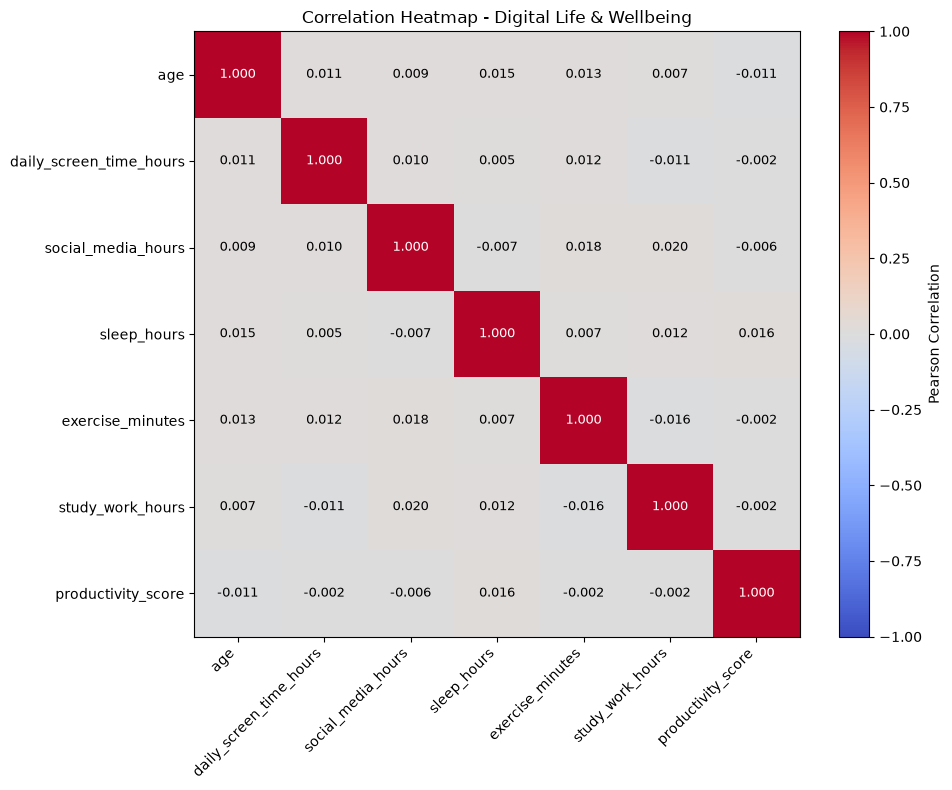

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix.astype(float),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(columns)),
    columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(columns)),
    columns
)

# Display correlation values inside each square
for i in range(len(columns)):
    for j in range(len(columns)):

        value = correlation_matrix.iloc[i, j]

        plt.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(value) > 0.5 else "black"
        )

plt.title("Correlation Heatmap - Digital Life & Wellbeing")
plt.tight_layout()
plt.show()


A heatmap is a data visualization technique that represents numerical values using different colors or color intensities, making patterns and relationships easier to identify.

In THE project, i created a Pearson correlation heatmap.

It visualizes the correlation coefficients between numerical variables.

cOLOUR : RED PERFECT POSITIVE
White near 0
Blue Perfect Negative


heatmap shows negligible pairwise linear associations among the numerical variables in the dataset version used to generate it.

It does not prove that the variables are statistically independent or that nonlinear relationships do not exist.


Q2) 
"Do highly productive observations have different lifestyle characteristics from less productive observations?"

In [12]:
P10 = df["productivity_score"].quantile(0.10)
P90 = df["productivity_score"].quantile(0.90)

print("10th percentile:", P10)
print("90th percentile:", P90)

10th percentile: 10.72
90th percentile: 90.65300000000002


In [13]:
low_productivity = df[
    df["productivity_score"] <= P10
]

high_productivity = df[
    df["productivity_score"] >= P90
]

print("Bottom 10%:", len(low_productivity))
print("Top 10%:", len(high_productivity))

Bottom 10%: 1101
Top 10%: 1100


In [14]:
def calculate_mean(values):
    valid = []

    for value in values:
        if pd.notna(value):
            valid.append(float(value))

    if len(valid) == 0:
        return None

    return sum(valid) / len(valid)

In [15]:
features = [
    "age",
    "sleep_hours",
    "daily_screen_time_hours",
    "social_media_hours",
    "exercise_minutes",
    "study_work_hours"
]

comparison = []

for column in features:

    low_mean = calculate_mean(low_productivity[column])
    high_mean = calculate_mean(high_productivity[column])

    difference = high_mean - low_mean

    comparison.append({
        "Feature": column,
        "Bottom 10% Mean": low_mean,
        "Top 10% Mean": high_mean,
        "Difference": difference
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Feature,Bottom 10% Mean,Top 10% Mean,Difference
0,age,32.891,32.325,-0.566
1,sleep_hours,5.987,5.984,-0.002
2,daily_screen_time_hours,6.574,6.515,-0.059
3,social_media_hours,4.296,4.190,-0.105
4,exercise_minutes,59.731,59.589,-0.142
5,study_work_hours,5.581,5.526,-0.055


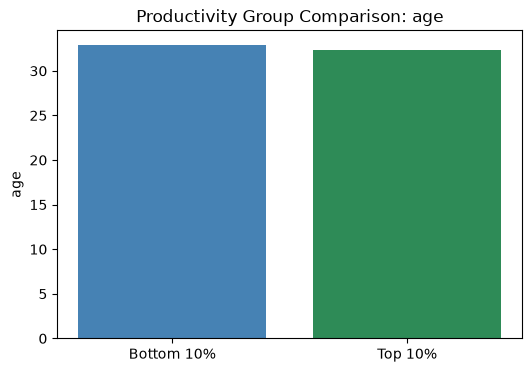

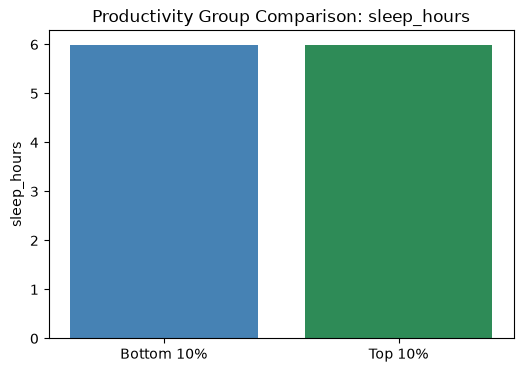

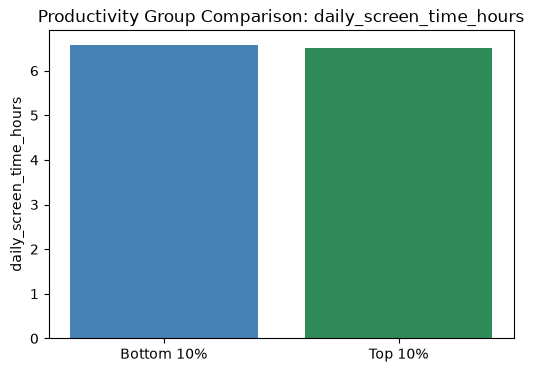

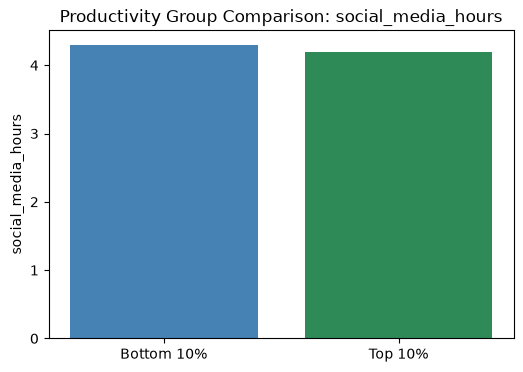

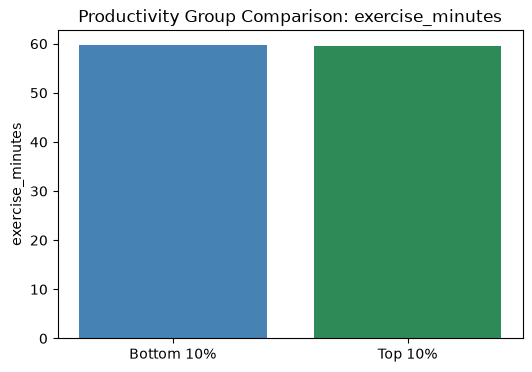

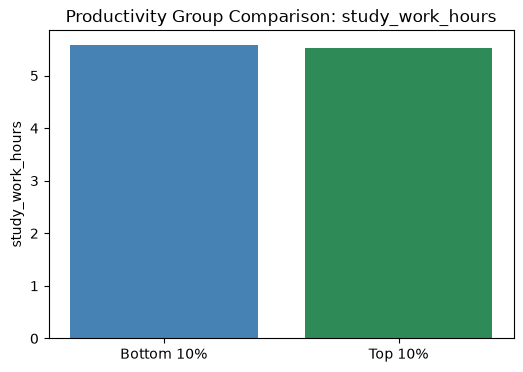

In [16]:
import matplotlib.pyplot as plt

for column in features:

    low_mean = calculate_mean(low_productivity[column])
    high_mean = calculate_mean(high_productivity[column])

    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Bottom 10%", "Top 10%"],
        [low_mean, high_mean],
        color=["steelblue", "seagreen"]
    )

    plt.ylabel(column)
    plt.title(f"Productivity Group Comparison: {column}")
    plt.ylim(bottom=0)

    plt.show()

In [17]:
display(comparison_df.round(3))

,Feature,Bottom 10% Mean,Top 10% Mean,Difference
0,age,32.891,32.325,-0.566
1,sleep_hours,5.987,5.984,-0.002
2,daily_screen_time_hours,6.574,6.515,-0.059
3,social_media_hours,4.296,4.190,-0.105
4,exercise_minutes,59.731,59.589,-0.142
5,study_work_hours,5.581,5.526,-0.055


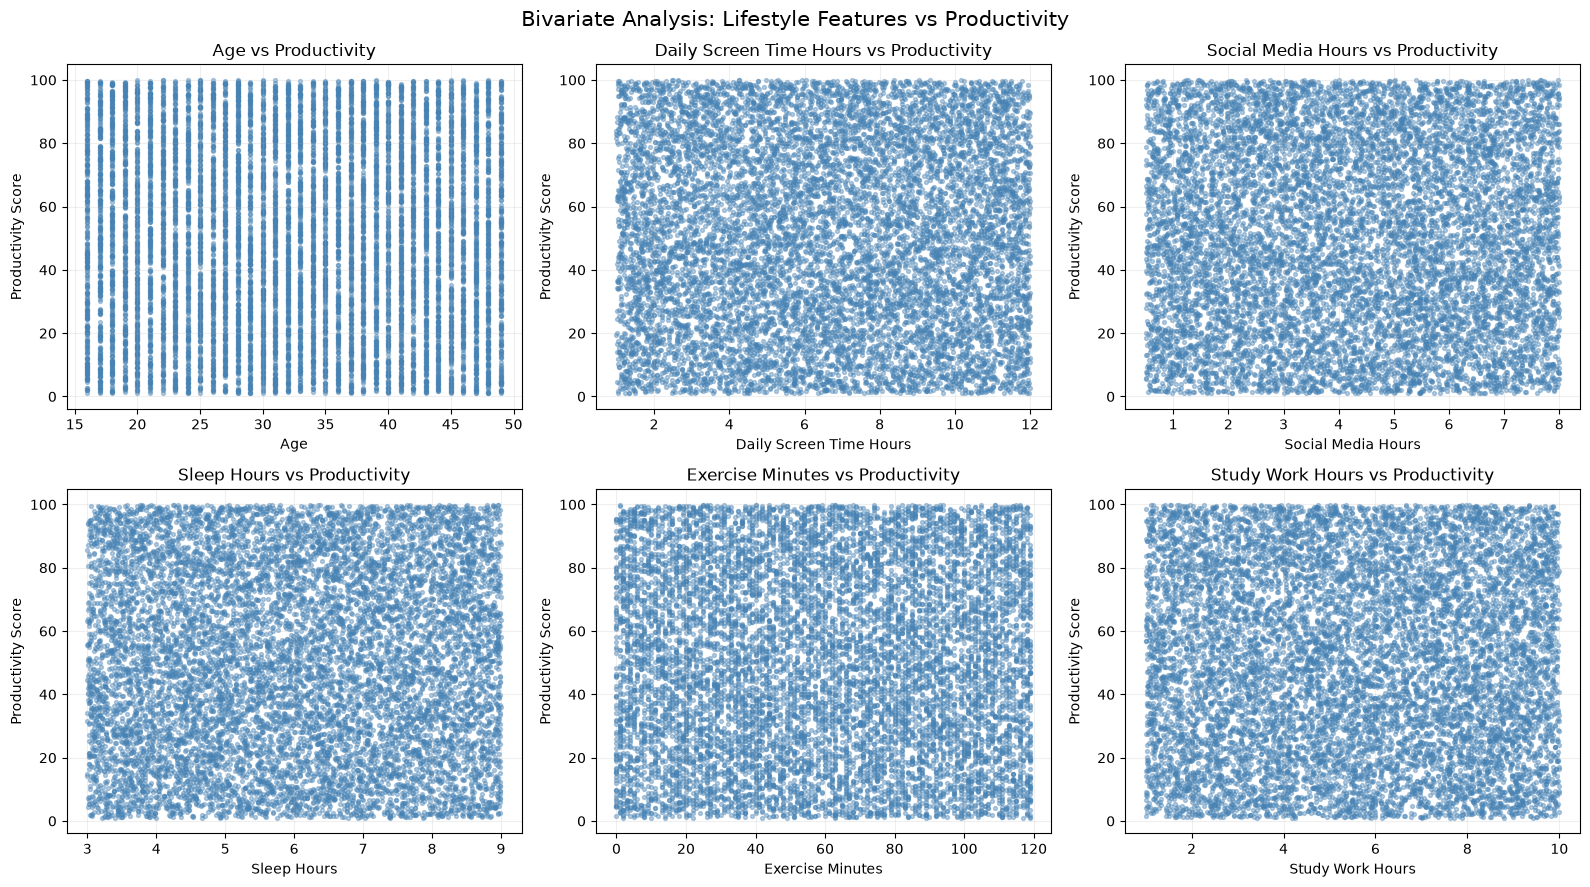

In [19]:

import matplotlib.pyplot as plt

features = [
    "age",
    "daily_screen_time_hours",
    "social_media_hours",
    "sleep_hours",
    "exercise_minutes",
    "study_work_hours"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, features):
    ax.scatter(
        df[feature],
        df["productivity_score"],
        alpha=0.4,
        s=8,
        color="steelblue"
    )

    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Productivity Score")
    ax.set_title(
        f"{feature.replace('_', ' ').title()} vs Productivity"
    )
    ax.grid(alpha=0.2)

plt.suptitle(
    "Bivariate Analysis: Lifestyle Features vs Productivity",
    fontsize=15
)

plt.tight_layout()
plt.show()


### Interpretation of Bivariate Scatterplots

Six scatterplots were generated to examine the relationships between productivity score and age, daily screen time, social-media usage, sleep duration, exercise duration, and study/work hours.

The plots show that productivity scores are widely distributed across the observed ranges of all six features. No clear upward, downward, or curved pattern is visually apparent.

The Age vs Productivity scatterplot displays vertical bands because age is recorded in discrete integer values.

These observations are consistent with the negligible Pearson correlation coefficients calculated earlier.

**Key Finding:** The selected lifestyle variables do not exhibit strong visible relationships with productivity in this dataset. This suggests that individual numerical features may have limited predictive usefulness for simple linear regression.

However, visual analysis alone cannot establish statistical independence or rule out more complex relationships.

Productivity Statistics by Stress Level:


,count,mean,median,std
stress_level,,,,
High,3604,50.32,49.44,28.68
Low,3715,50.62,50.11,29.17
Medium,3681,50.91,50.84,28.66


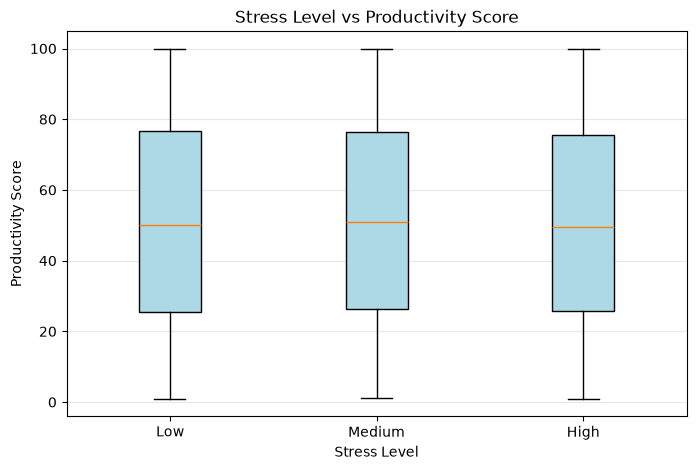

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Select stress categories
stress_levels = ["Low", "Medium", "High"]

# Collect productivity scores for each category
groups = []

for level in stress_levels:
    scores = df.loc[
        df["stress_level"] == level,
        "productivity_score"
    ].dropna()

    groups.append(scores)

# Display summary statistics
stress_summary = df.groupby("stress_level")[
    "productivity_score"
].agg(["count", "mean", "median", "std"])

print("Productivity Statistics by Stress Level:")
display(stress_summary.round(2))

# Create box plot
plt.figure(figsize=(8, 5))

plt.boxplot(
    groups,
    tick_labels=stress_levels,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue")
)

plt.title("Stress Level vs Productivity Score")
plt.xlabel("Stress Level")
plt.ylabel("Productivity Score")
plt.grid(axis="y", alpha=0.3)

plt.show()


['user_id', 'age', 'daily_screen_time_hours', 'social_media_hours', 'sleep_hours', 'exercise_minutes', 'study_work_hours', 'productivity_score', 'stress_level', 'platform']


KeyError: 'social_media_platform'